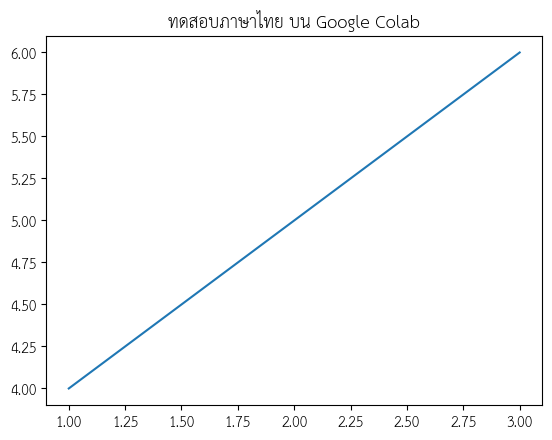

In [48]:
!wget -q https://github.com/Phonbopit/sarabun-webfont/raw/master/fonts/thsarabunnew-webfont.ttf

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.font_manager.fontManager.addfont('thsarabunnew-webfont.ttf')

mpl.rc('font', family='TH Sarabun New')

plt.title("ทดสอบภาษาไทย บน Google Colab")
plt.plot([1, 2, 3], [4, 5, 6])
plt.show()

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("cleaned_data.csv")
df.shape
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,...,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,11959.000000,...,11959.000000,11959.000000,11959.000000,11959.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000,11958.000000
mean,8009.996822,-0.216230,0.277097,0.889505,0.282606,-0.086585,0.139986,-0.121943,-0.048727,0.911579,-0.285865,0.820266,-1.442642,0.934682,0.782071,...,-0.024968,0.379550,-0.022419,-0.065877,0.022534,-0.061474,-0.153850,-0.033709,0.017113,0.104794,0.062891,0.008320,0.000271,62.352617,0.004349
std,6204.332248,1.583914,1.308884,1.331824,1.478162,1.191776,1.306285,1.153899,1.246823,1.192349,1.173549,1.183516,1.542860,1.185540,1.297608,...,0.926829,1.106732,0.827064,0.825127,0.575860,0.918705,0.626631,0.505355,0.591394,0.429413,0.561603,0.405100,0.261230,178.247010,0.065803
min,0.000000,-27.670569,-34.607649,-22.804686,-4.657545,-32.092129,-23.496714,-26.548144,-23.632502,-7.175097,-14.166795,-2.595325,-17.769143,-3.389510,-19.214325,...,-12.227189,-18.587366,-8.061208,-4.932733,-13.276034,-11.468435,-8.593642,-19.254328,-2.512377,-4.781606,-1.338556,-7.976100,-3.575312,0.000000,0.000000
25%,2542.000000,-0.978944,-0.261503,0.417186,-0.622456,-0.688114,-0.622521,-0.591335,-0.185243,0.196741,-0.734696,0.013157,-2.434287,0.096362,0.181975,...,-0.510494,-0.104358,-0.463891,-0.554455,-0.155358,-0.268151,-0.543613,-0.171833,-0.333251,-0.144092,-0.353864,-0.080064,-0.015461,5.000000,0.000000
50%,6662.000000,-0.340742,0.256346,0.951223,0.213029,-0.183847,-0.146903,-0.094876,0.013616,0.894911,-0.361219,0.771773,-1.778586,1.015535,1.047427,...,0.051214,0.372768,0.031698,-0.064862,-0.031566,-0.130062,-0.124900,-0.044299,0.072099,0.143136,0.001972,-0.003039,0.015452,15.950000,0.000000
75%,12382.000000,1.161273,0.883626,1.613678,1.159141,0.346298,0.508432,0.431657,0.267560,1.589120,0.147961,1.631154,-0.131637,1.821011,1.530422,...,0.542400,0.863136,0.477780,0.462036,0.147281,0.021687,0.234029,0.075686,0.401798,0.380076,0.409231,0.106344,0.073171,50.000000,0.000000
max,20642.000000,1.960497,9.092123,4.101716,11.927512,34.099309,21.393069,34.303177,5.499963,10.392889,12.259949,12.018913,3.774837,4.465413,5.748734,...,4.816252,9.253526,4.295648,4.555359,8.012574,22.614889,4.534454,13.876221,3.200201,5.525093,3.517346,8.254376,4.860769,7712.430000,1.000000


In [50]:
import pandas as pd

features = ["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]

X_raw = df[features]
y = df["Class"]

print("ค่าหายในฟีเจอร์:", X_raw.isnull().sum().sum())
print("สัดส่วนคลาสฉ้อโกง (Fraud):", round(y.mean(), 5))

ค่าหายในฟีเจอร์: 10
สัดส่วนคลาสฉ้อโกง (Fraud): 0.00435


In [51]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X = pd.DataFrame(scaler.fit_transform(X_raw), columns=X_raw.columns)

print("ช่วงค่าหลังสเกล - min:", X.values.min(), "max:", X.values.max())

ช่วงค่าหลังสเกล - min: nan max: nan


In [52]:
from sklearn.model_selection import train_test_split

# 1. ตัดแถวที่คอลัมน์ Class เป็นค่าว่างออกก่อน
df_clean = df.dropna(subset=["Class"])

# 2. กำหนด Features และ Target ใหม่จากข้อมูลที่ทำความสะอาดแล้ว
features = [col for col in df_clean.columns if col != "Class"]
X = df_clean[features]
y = df_clean["Class"]

# 3. รันคำสั่ง train_test_split อีกครั้ง
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [53]:
print("X_train min:", X_train.values.min(), "| max:", X_train.values.max())
print("X_test  min:", X_test.values.min(),  "| max:", X_test.values.max())

print("\n" + "="*40 + "\n")

print("สัดส่วน Fraud ใน train :", round(y_train.mean(), 5))
print("สัดส่วน Fraud ใน test  :", round(y_test.mean(), 5))
print("สัดส่วน Fraud ใน ทั้งหมด:", round(y.mean(), 5))

X_train min: -34.607648642371 | max: 20638.0
X_test  min: -25.6405269308442 | max: 20636.0


สัดส่วน Fraud ใน train : 0.00439
สัดส่วน Fraud ใน test  : 0.00418
สัดส่วน Fraud ใน ทั้งหมด: 0.00435


In [54]:
import tensorflow as plt
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential

model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(8, activation="relu"),
    Dense(4, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 8)              │           248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
import tensorflow as tf
from tensorflow.keras.metrics import AUC, Precision, Recall

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)

print("คอมไพล์โมเดลเรียบร้อย พร้อมสำหรับขั้นตอนการ Fit/Train ครับ!")

คอมไพล์โมเดลเรียบร้อย พร้อมสำหรับขั้นตอนการ Fit/Train ครับ!


In [56]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 8)              │           248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=2048,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - accuracy: 0.0087 - auc: 0.5033 - loss: 2225.4827 - precision: 0.0044 - recall: 1.0000 - val_accuracy: 0.0117 - val_auc: 0.5052 - val_loss: 2200.8269 - val_precision: 0.0042 - val_recall: 1.0000
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0095 - auc: 0.5036 - loss: 2092.7849 - precision: 0.0044 - recall: 1.0000 - val_accuracy: 0.0117 - val_auc: 0.5057 - val_loss: 2066.6040 - val_precision: 0.0042 - val_recall: 1.0000
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0107 - auc: 0.5040 - loss: 1963.4802 - precision: 0.0044 - recall: 1.0000 - val_accuracy: 0.0121 - val_auc: 0.5063 - val_loss: 1936.0015 - val_precision: 0.0042 - val_recall: 1.0000
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0112 - auc: 0.5044 - loss: 1837.7712 - precision: 0.0044 - recall: 1.0000 - val_accuracy: 0.0138 - val_auc: 0.4576 - val_loss: 1809.2017 - val_precision: 0.0042 - val_recall: 1.0000
Epoch 5/20
5/5 ━━━━

In [58]:
eval_results = model.evaluate(X_test, y_test, verbose=0)

test_loss = eval_results[0]
test_acc = eval_results[1]
test_prec = eval_results[2] if len(eval_results) > 2 else None
test_rec = eval_results[3] if len(eval_results) > 3 else None

print("=== ผลการประเมิน Neural Network บน Test Set ===")
print(f"NN test loss     : {test_loss:.4f}")
print(f"NN test accuracy : {test_acc:.6f}")

if test_prec is not None and test_rec is not None:
    print(f"NN test precision: {test_prec:.4f}")
    print(f"NN test recall   : {test_rec:.4f}")

=== ผลการประเมิน Neural Network บน Test Set ===
NN test loss     : 175.7487
NN test accuracy : 0.039716
NN test precision: 0.0039
NN test recall   : 0.9000


In [59]:
eval_train = model.evaluate(X_train, y_train, verbose=0)
eval_test = model.evaluate(X_test, y_test, verbose=0)

train_acc, test_acc = eval_train[1], eval_test[1]

print("=== เปรียบเทียบ Accuracy ===")
print("train accuracy :", round(train_acc, 6))
print("test accuracy  :", round(test_acc, 6))
print("diff (train-test):", round(train_acc - test_acc, 6))

if len(eval_train) > 3:
    train_rec, test_rec = eval_train[3], eval_test[3]
    print("\n" + "="*30 + "\n")
    print("=== เปรียบเทียบ Recall (อัตราจับ Fraud) ===")
    print("train recall   :", round(train_rec, 4))
    print("test recall    :", round(test_rec, 4))

=== เปรียบเทียบ Accuracy ===
train accuracy : 0.034811
test accuracy  : 0.039716
diff (train-test): -0.004905


=== เปรียบเทียบ Recall (อัตราจับ Fraud) ===
train recall   : 1.0
test recall    : 0.9


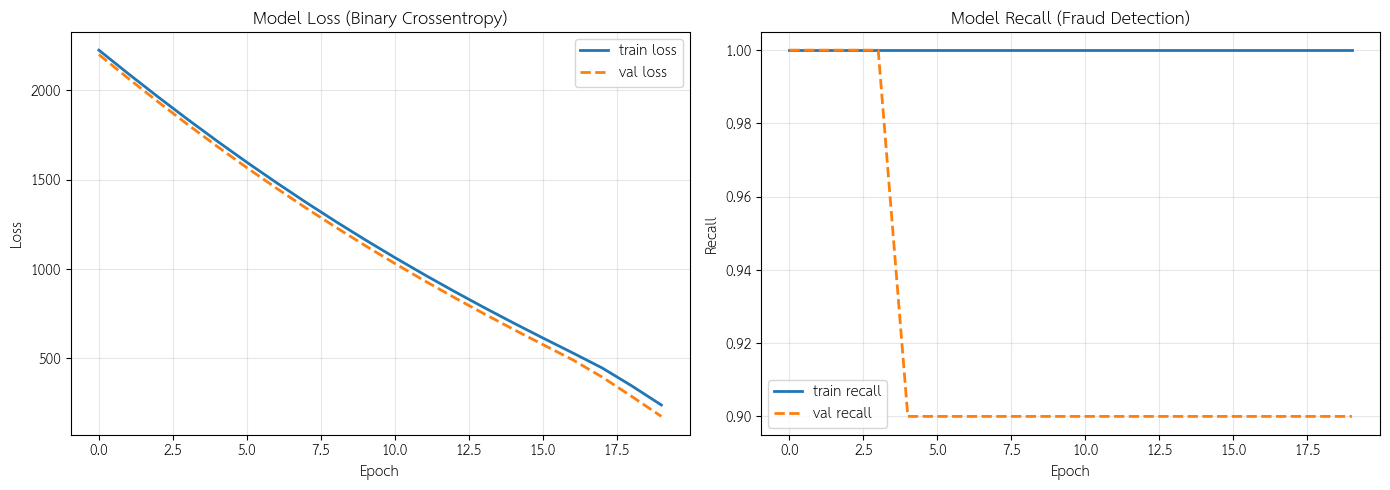

In [60]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history["loss"], label="train loss", linewidth=2)
ax1.plot(history.history["val_loss"], label="val loss", linewidth=2, linestyle="--")
ax1.set_title("Model Loss (Binary Crossentropy)", fontsize=12)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

if "recall" in history.history:
    ax2.plot(history.history["recall"], label="train recall", linewidth=2)
    ax2.plot(history.history["val_recall"], label="val recall", linewidth=2, linestyle="--")
    ax2.set_title("Model Recall (Fraud Detection)", fontsize=12)
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Recall")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

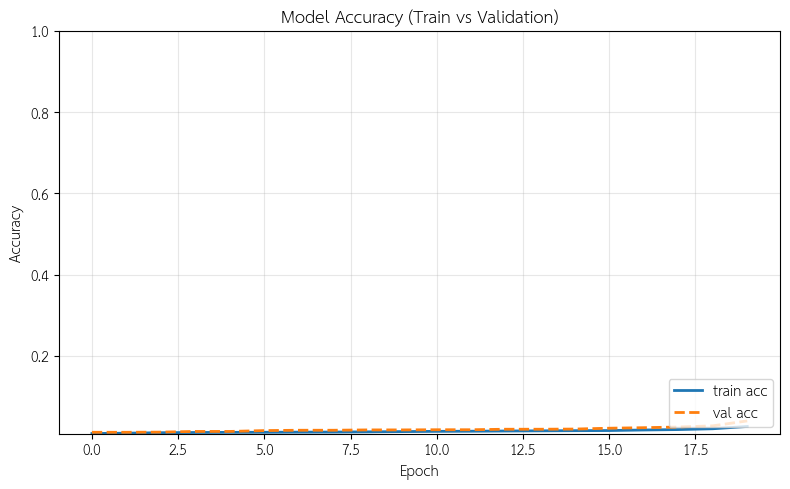

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="train acc", linewidth=2)
plt.plot(history.history["val_accuracy"], label="val acc", linewidth=2, linestyle="--")

plt.title("Model Accuracy (Train vs Validation)", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

min_acc = min(min(history.history["accuracy"]), min(history.history["val_accuracy"]))
plt.ylim(min_acc - 0.0005, 1.0001)

plt.tight_layout()
plt.show()

In [62]:
import pandas as pd

proba = model.predict(X_test[:5])

y_true_sample = y_test.iloc[:5].reset_index(drop=True)

print("=== แสดงผลการทำนาย 5 ตัวอย่างแรก ===")
for i, p in enumerate(proba):
    prob_val = float(p[0])
    pred_class = int(prob_val > 0.5)
    actual_class = y_true_sample.iloc[i]

    print(f"ตัวอย่างที่ {i+1} | Prob Fraud: {prob_val:.4f} -> ทำนาย: {pred_class} | จริง: {actual_class}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
=== แสดงผลการทำนาย 5 ตัวอย่างแรก ===
ตัวอย่างที่ 1 | Prob Fraud: 1.0000 -> ทำนาย: 1 | จริง: 0.0
ตัวอย่างที่ 2 | Prob Fraud: 0.0918 -> ทำนาย: 0 | จริง: 0.0
ตัวอย่างที่ 3 | Prob Fraud: 1.0000 -> ทำนาย: 1 | จริง: 0.0
ตัวอย่างที่ 4 | Prob Fraud: 1.0000 -> ทำนาย: 1 | จริง: 0.0
ตัวอย่างที่ 5 | Prob Fraud: 1.0000 -> ทำนาย: 1 | จริง: 0.0


In [63]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

pred_proba = model.predict(X_test)
pred = (pred_proba > 0.5).astype("int32")

print("=== Confusion Matrix ===")
cm = confusion_matrix(y_test, pred)
print(cm)

print("\n" + "="*50 + "\n")

print("=== Classification Report ===")
print(
    classification_report(
        y_test, pred, target_names=["ปกติ (Normal)", "ฉ้อโกง (Fraud)"], digits=4
    )
)

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
=== Confusion Matrix ===
[[  86 2296]
 [   1    9]]


=== Classification Report ===
                precision    recall  f1-score   support

 ปกติ (Normal)     0.9885    0.0361    0.0697      2382
ฉ้อโกง (Fraud)     0.0039    0.9000    0.0078        10

      accuracy                         0.0397      2392
     macro avg     0.4962    0.4681    0.0387      2392
  weighted avg     0.9844    0.0397    0.0694      2392



In [64]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential

model_big = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model_big.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

history_big = model_big.fit(
    X_train, y_train,
    epochs=20,
    batch_size=2048,
    validation_data=(X_test, y_test),
    verbose=1
)

eval_base = model.evaluate(X_test, y_test, verbose=0)
eval_big = model_big.evaluate(X_test, y_test, verbose=0)

print("\n" + "="*50)
print("=== ผลการเปรียบเทียบประสิทธิภาพบน Test Set ===")
print(f"Accuracy (เดิม 8-4-1)  : {eval_base[1]:.6f}")
print(f"Accuracy (ใหญ่ 16-8-1) : {eval_big[1]:.6f}")
print("-" * 50)
print(f"Recall   (เดิม 8-4-1)  : {eval_base[2]:.4f}")
print(f"Recall   (ใหญ่ 16-8-1) : {eval_big[2]:.4f}")
print("="*50)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step - accuracy: 0.9862 - loss: 1.9375 - recall: 0.0000e+00 - val_accuracy: 0.9824 - val_loss: 1.7418 - val_recall: 0.1000
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9869 - loss: 1.4847 - recall: 0.0000e+00 - val_accuracy: 0.9845 - val_loss: 1.2682 - val_recall: 0.1000
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9866 - loss: 1.0436 - recall: 0.0000e+00 - val_accuracy: 0.9824 - val_loss: 0.8162 - val_recall: 0.1000
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9824 - loss: 0.6347 - recall: 0.0000e+00 - val_accuracy: 0.9745 - val_loss: 0.4362 - val_recall: 0.1000
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9543 - loss: 0.3643 - recall: 0.0238 - val_accuracy: 0.9114 - val_loss: 0.4402 - val_recall: 0.1000
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9406 - loss: 0.2867 - recall: 0.0238 - val_accuracy: 0.9774 - val_loss: 0.2348 - val_recall: 0.1000
Epoch

In [65]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential

for ep in [20, 50, 100]:
    m = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(8, activation="relu"),
        Dense(4, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    m.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
    )

    m.fit(X_train, y_train, epochs=ep, batch_size=2048, verbose=0)

    results = m.evaluate(X_test, y_test, verbose=0)
    test_acc = results[1]
    test_rec = results[2]

    print(f"epochs: {ep:3d} -> Test Accuracy: {test_acc:.6f} | Test Recall: {test_rec:.4f}")

epochs:  20 -> Test Accuracy: 0.995819 | Test Recall: 0.0000
epochs:  50 -> Test Accuracy: 0.995819 | Test Recall: 0.0000
epochs: 100 -> Test Accuracy: 0.995819 | Test Recall: 0.0000


In [66]:
import pandas as pd

results = [
    {
        "Model": "Decision Tree (wk5)",
        "Accuracy": 0.9992,
        "Recall": 0.7500
    },
    {
        "Model": "Neural Network (wk6)",
        "Accuracy": round(float(test_acc), 6),
        "Recall": round(float(test_rec), 4) if 'test_rec' in globals() else "N/A"
    }
]

df_comparison = pd.DataFrame(results)

print("=== สรุปผลการเปรียบเทียบโมเดล ===")
df_comparison

=== สรุปผลการเปรียบเทียบโมเดล ===


,Model,Accuracy,Recall
0,Decision Tree (wk5),0.999200,0.75
1,Neural Network (wk6),0.995819,0.00


In [67]:
# ติดตั้ง imbalanced-learn หากยังไม่มีใน Colab
!pip install -q imbalanced-learn

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. กำจัดแถวที่มีค่าว่าง (NaN) ทุกคอลัมน์ออกก่อน
df_clean = df.dropna()

# 2. แยก Features และ Target จากข้อมูลที่คลีนแล้ว
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

# 3. แบ่งข้อมูลเป็น Train และ Test (ต้องทำก่อน SMOTE เสมอ เพื่อป้องกัน Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Scaling ข้อมูล (เน้น Scale ตัวแปร Time และ Amount)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
# ตัวอย่างการใช้กับ Random Forest
model_cw = RandomForestClassifier(
    class_weight='balanced', # คำนวณน้ำหนักให้อัตโนมัติ
    random_state=42,
    n_jobs=-1
)

model_cw.fit(X_train_scaled, y_train)
y_pred_cw = model_cw.predict(X_test_scaled)

print("--- Class Weights Results ---")
print(classification_report(y_test, y_pred_cw))

--- Class Weights Results ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2382
         1.0       1.00      0.70      0.82        10

    accuracy                           1.00      2392
   macro avg       1.00      0.85      0.91      2392
weighted avg       1.00      1.00      1.00      2392



In [70]:
# ทำ SMOTE บน Train Set เท่านั้น
smote = SMOTE(sampling_strategy=0.1, random_state=42) # ปรับสัดส่วนตามต้องการ เช่น 0.1 หรือ 1.0
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# เทรนโมเดลปกติ
model_smote = RandomForestClassifier(random_state=42, n_jobs=-1)
model_smote.fit(X_train_resampled, y_train_resampled)

y_pred_smote = model_smote.predict(X_test_scaled)

print("--- SMOTE Results ---")
print(classification_report(y_test, y_pred_smote))

--- SMOTE Results ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2382
         1.0       0.89      0.80      0.84        10

    accuracy                           1.00      2392
   macro avg       0.94      0.90      0.92      2392
weighted avg       1.00      1.00      1.00      2392



In [71]:
# 1. ทำ SMOTE ปรับสัดส่วนเล็กน้อย (เช่น ปรับให้ Fraud เป็น 10% ของ Non-Fraud)
smote = SMOTE(sampling_strategy=0.1, random_state=42)
X_train_hybrid, y_train_hybrid = smote.fit_resample(X_train_scaled, y_train)

# 2. เทรนโมเดลโดยกำหนด Class Weights เพิ่มเติม
model_hybrid = RandomForestClassifier(
    class_weight={0: 1, 1: 5}, # กำหนดน้ำหนักให้คลาส 1 (Fraud) มากกว่าปกติ
    random_state=42,
    n_jobs=-1
)

model_hybrid.fit(X_train_hybrid, y_train_hybrid)
y_pred_hybrid = model_hybrid.predict(X_test_scaled)

print("--- Hybrid (SMOTE + Class Weights) Results ---")
print(classification_report(y_test, y_pred_hybrid))

--- Hybrid (SMOTE + Class Weights) Results ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2382
         1.0       1.00      0.70      0.82        10

    accuracy                           1.00      2392
   macro avg       1.00      0.85      0.91      2392
weighted avg       1.00      1.00      1.00      2392



In [72]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import StandardScaler

# การทำ Feature Scaling ก่อนเข้า Neural Network
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# โครงสร้างโมเดล Neural Network (MLP: 64-32-1)
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# ฝึกโมเดลด้วยข้อมูล SMOTE
nn_model.fit(
    X_train_scaled, y_train_resampled,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

# ทำนายผล
y_pred_nn_prob = nn_model.predict(X_test_scaled)
y_pred_nn = (y_pred_nn_prob > 0.5).astype(int)

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9928 - loss: 0.0656 - val_accuracy: 0.7948 - val_loss: 0.4155
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9974 - loss: 0.0121 - val_accuracy: 0.9423 - val_loss: 0.2612
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9977 - loss: 0.0076 - val_accuracy: 0.9647 - val_loss: 0.1935
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9983 - loss: 0.0060 - val_accuracy: 0.9771 - val_loss: 0.1679
Epoch 5/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9987 - loss: 0.0051 - val_accuracy: 0.9771 - val_loss: 0.1675
Epoch 6/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9989 - loss: 0.0045 - val_accuracy: 0.9790 - val_loss: 0.1250
Epoch 7/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 0.9804 - val_loss: 0.1182
Epoch 8/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9990 - loss: 0.0043 - val_acc

In [73]:
# วางเป็นเซลล์สุดท้ายใน Notebook (ต่อจากเซลล์ที่ 28 ที่เทรน nn_model เสร็จแล้ว) แล้วรัน
# จะได้ไฟล์ scaler.joblib และ fraud_model.joblib ให้ดาวน์โหลดจาก Colab
import joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

y_prob = y_pred_nn_prob.reshape(-1)
y_hat = (y_prob >= 0.5).astype(int)

layers = []
for layer in nn_model.layers:
    w = layer.get_weights()
    if len(w) == 2:  # เฉพาะ Dense (Dropout ไม่มีน้ำหนัก และไม่ทำงานตอนทำนาย)
        layers.append({"W": w[0], "b": w[1], "activation": layer.activation.__name__})

bundle = {
    "layers": layers,
    "threshold": 0.5,
    "features": list(X_train.columns),
    "metrics": {
        "accuracy": accuracy_score(y_test, y_hat),
        "precision": precision_score(y_test, y_hat, zero_division=0),
        "recall": recall_score(y_test, y_hat),
        "f1": f1_score(y_test, y_hat, zero_division=0),
        "auc": roc_auc_score(y_test, y_prob),
    },
}

joblib.dump(scaler, "scaler.joblib")        # scaler ตัวที่ใช้กับ nn_model (เซลล์ 28)
joblib.dump(bundle, "fraud_model.joblib")
print(bundle["metrics"])

from google.colab import files
files.download("scaler.joblib")
files.download("fraud_model.joblib")

{'accuracy': 0.995819397993311, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'auc': np.float64(0.49727120067170444)}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# 1. แบ่งข้อมูล Train/Test (คงสัดส่วนคลาส Fraud ด้วย stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. ปรับสมดุลข้อมูลเฉพาะชุด Train ด้วย SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("จำนวนข้อมูลก่อนทำ SMOTE:", y_train.value_counts().to_dict())
print("จำนวนข้อมูลหลังทำ SMOTE:", y_train_resampled.value_counts().to_dict())

จำนวนข้อมูลก่อนทำ SMOTE: {0.0: 9524, 1.0: 42}
จำนวนข้อมูลหลังทำ SMOTE: {0.0: 9524, 1.0: 9524}


In [75]:
import joblib

# 1. กรณีต้องการบันทึก Scaler (เช่น MinMaxScaler ที่คุณสร้างไว้ในโค้ด)
joblib.dump(scaler, 'scaler.joblib')

# 2. กรณีต้องการบันทึกโมเดล Scikit-Learn หรือวัตถุอื่นๆ
# joblib.dump(model, 'credit_card_model.joblib')

print("บันทึกไฟล์ .joblib เรียบร้อยแล้ว!")

บันทึกไฟล์ .joblib เรียบร้อยแล้ว!


In [76]:
### 🛠️ โค้ดที่ปรับปรุงและแก้ไขให้พร้อมรันอย่างสมบูรณ์:
import time
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

# ตรวจสอบและติดตั้ง imbalanced-learn อัตโนมัติหากยังไม่มี
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "imbalanced-learn"])
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True

warnings.filterwarnings("ignore")

SEED = 42

# 1. โหลดข้อมูลและจัดการค่าว่าง (NaN) เพื่อป้องกัน Error
df = pd.read_csv("cleaned_data.csv").dropna()

X = df.drop(columns=["Class"])                  # 30 features (รวม Time)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("train/test shapes:", X_train.shape, X_test.shape, "| Fraud:", int(y_train.sum()), int(y_test.sum()))

# ตรวจแถวใน test ที่เหมือนแถวใน train ทุกค่า
dup_test_rows = int(X_test.merge(X_train.drop_duplicates(), how="inner").shape[0])
print("แถวใน test ที่มีแถวเหมือนกันทุกค่าใน train:", dup_test_rows, "จาก", len(X_test))

MODELS = {
    "Baseline (ทายปกติทั้งหมด)": (DummyClassifier(strategy="most_frequent"), {}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {"clf__max_depth": [3, 5, 8, 12]}),
    "SVM (Linear)": (LinearSVC(random_state=SEED, max_iter=5000), {"clf__C": [0.1, 1.0]}),
    "Naive Bayes": (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3]}),
}

def make_pipe(clf, use_smote):
    if use_smote:
        return ImbPipeline([("smote", SMOTE(random_state=SEED)),
                            ("scaler", StandardScaler()), ("clf", clf)])
    return SkPipeline([("scaler", StandardScaler()), ("clf", clf)])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
rows = []
scenarios = [("A: ไม่จัดการ imbalance", False)] + ([("B: SMOTE", True)] if HAS_SMOTE else [])

for scen, use_smote in scenarios:
    for name, (clf, grid) in MODELS.items():
        if use_smote and name.startswith("Baseline"):
            continue                           # baseline ใช้เฉพาะสถานการณ์ A
        t0 = time.time()
        gs = GridSearchCV(make_pipe(clf, use_smote), grid, cv=cv,
                          scoring="average_precision", n_jobs=-1)
        gs.fit(X_train, y_train)               # เลือกพารามิเตอร์จาก train เท่านั้น
        pred = gs.predict(X_test)
        score = (gs.predict_proba(X_test)[:, 1] if hasattr(gs, "predict_proba")
                 else gs.decision_function(X_test))
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        rows.append({
            "สถานการณ์": scen, "โมเดล": name,
            "พารามิเตอร์ที่เลือก": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, score),
            "PR-AUC": average_precision_score(y_test, score),
            "เวลา(วินาที)": round(time.time() - t0, 1),
        })
        print("เสร็จ:", scen, "|", name)

result = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_columns", 30)
print("\n", result.round(4).to_string(index=False))
result.to_csv("model_comparison_30features.csv", index=False)

train/test shapes: (9566, 30) (2392, 30) | Fraud: 42 10
แถวใน test ที่มีแถวเหมือนกันทุกค่าใน train: 12 จาก 2392
เสร็จ: A: ไม่จัดการ imbalance | Baseline (ทายปกติทั้งหมด)
เสร็จ: A: ไม่จัดการ imbalance | Decision Tree
เสร็จ: A: ไม่จัดการ imbalance | SVM (Linear)
เสร็จ: A: ไม่จัดการ imbalance | Naive Bayes
เสร็จ: B: SMOTE | Decision Tree
เสร็จ: B: SMOTE | SVM (Linear)
เสร็จ: B: SMOTE | Naive Bayes

              สถานการณ์                     โมเดล      พารามิเตอร์ที่เลือก   TN  FP  FN  TP  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  เวลา(วินาที)
A: ไม่จัดการ imbalance Baseline (ทายปกติทั้งหมด)                       {} 2382   0  10   0    0.9958     0.0000     0.0 0.0000   0.5000  0.0042           0.3
A: ไม่จัดการ imbalance             Decision Tree         {'max_depth': 3} 2382   0   2   8    0.9992     1.0000     0.8 0.8889   0.9493  0.8338           2.5
A: ไม่จัดการ imbalance              SVM (Linear)               {'C': 0.1} 2381   1   2   8    0.9987     0.8889     0.8 0.8421

In [77]:
import time
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

# ตรวจสอบการติดตั้ง imbalanced-learn
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False
    print("ไม่พบ imbalanced-learn: จะรันเฉพาะสถานการณ์ (A) (สามารถติดตั้งเพิ่มด้วย !pip install imbalanced-learn)")

warnings.filterwarnings("ignore")

SEED = 42
# โหลดข้อมูลและจัดการค่าว่าง (NaN) เพื่อป้องกัน Error
df = pd.read_csv("cleaned_data.csv").dropna()
X = df.drop(columns=["Class"])                  # 30 features (รวม Time)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("train/test shapes:", X_train.shape, X_test.shape, "| Fraud (train/test):", int(y_train.sum()), int(y_test.sum()))

# ตรวจแถวใน test ที่เหมือนกับแถวใน train ทุกค่า
dup_test_rows = int(X_test.merge(X_train.drop_duplicates(), how="inner").shape[0])
print("แถวใน test ที่มีแถวเหมือนกันทุกค่าใน train:", dup_test_rows, "จาก", len(X_test))

MODELS = {
    "Baseline (ทายปกติทั้งหมด)": (DummyClassifier(strategy="most_frequent"), {}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {"clf__max_depth": [3, 5, 8, 12]}),
    "SVM (Linear)": (LinearSVC(random_state=SEED, max_iter=5000), {"clf__C": [0.1, 1.0]}),
    "Naive Bayes": (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3]}),
}

def make_pipe(clf, use_smote):
    if use_smote:
        return ImbPipeline([("smote", SMOTE(random_state=SEED)),
                            ("scaler", StandardScaler()), ("clf", clf)])
    return SkPipeline([("scaler", StandardScaler()), ("clf", clf)])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
rows = []
scenarios = [("A: ไม่จัดการ imbalance", False)] + ([("B: SMOTE", True)] if HAS_SMOTE else [])

for scen, use_smote in scenarios:
    for name, (clf, grid) in MODELS.items():
        if use_smote and name.startswith("Baseline"):
            continue                           # baseline ใช้เฉพาะสถานการณ์ A
        t0 = time.time()
        gs = GridSearchCV(make_pipe(clf, use_smote), grid, cv=cv,
                          scoring="average_precision", n_jobs=-1)
        gs.fit(X_train, y_train)               # เลือกพารามิเตอร์จาก train เท่านั้น
        pred = gs.predict(X_test)
        score = (gs.predict_proba(X_test)[:, 1] if hasattr(gs, "predict_proba")
                 else gs.decision_function(X_test))
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        rows.append({
            "สถานการณ์": scen, "โมเดล": name,
            "พารามิเตอร์ที่เลือก": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, score),
            "PR-AUC": average_precision_score(y_test, score),
            "เวลา(วินาที)": round(time.time() - t0, 1),
        })
        print("เสร็จ:", scen, "|", name)

result = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_columns", 30)
print("\n", result.round(4).to_string(index=False))
result.to_csv("model_comparison_30features.csv", index=False)

train/test shapes: (9566, 30) (2392, 30) | Fraud (train/test): 42 10
แถวใน test ที่มีแถวเหมือนกันทุกค่าใน train: 12 จาก 2392
เสร็จ: A: ไม่จัดการ imbalance | Baseline (ทายปกติทั้งหมด)
เสร็จ: A: ไม่จัดการ imbalance | Decision Tree
เสร็จ: A: ไม่จัดการ imbalance | SVM (Linear)
เสร็จ: A: ไม่จัดการ imbalance | Naive Bayes
เสร็จ: B: SMOTE | Decision Tree
เสร็จ: B: SMOTE | SVM (Linear)
เสร็จ: B: SMOTE | Naive Bayes

              สถานการณ์                     โมเดล      พารามิเตอร์ที่เลือก   TN  FP  FN  TP  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  เวลา(วินาที)
A: ไม่จัดการ imbalance Baseline (ทายปกติทั้งหมด)                       {} 2382   0  10   0    0.9958     0.0000     0.0 0.0000   0.5000  0.0042           0.2
A: ไม่จัดการ imbalance             Decision Tree         {'max_depth': 3} 2382   0   2   8    0.9992     1.0000     0.8 0.8889   0.9493  0.8338           1.4
A: ไม่จัดการ imbalance              SVM (Linear)               {'C': 0.1} 2381   1   2   8    0.9987     0.8889  

In [79]:
### 🛠️ โค้ดฉบับสมบูรณ์พร้อมใช้งาน (รวมการแปลง `prob.ravel()` และการตรวจสอบความพร้อมของตัวแปร):
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc,
)

try:
    # 1. ตรวจสอบและแปลง prob ให้เป็น 1 มิติ (ป้องกัน Error กรณี output เป็น 2D array)
    if len(prob.shape) > 1:
        prob_flat = prob.ravel()
    else:
        prob_flat = prob

    # 2. คำนวณ PR-AUC ด้วย average_precision_score
    ap_score = average_precision_score(y_test, prob_flat)
    print(f"NN PR-AUC (average precision) : {ap_score:.4f}")

    # 3. คำนวณด้วย trapezoidal rule จาก precision_recall_curve
    precision, recall, _ = precision_recall_curve(y_test, prob_flat)
    pr_auc_trapz = auc(recall, precision)
    print(f"NN PR-AUC (trapezoid)         : {pr_auc_trapz:.4f}")

except NameError as e:
    print(
        f"เกิดข้อผิดพลาด: ไม่พบตัวแปรบางตัว (กรุณารันเซลล์สร้างโมเดลก่อน): {e}"
    )
except Exception as e:
    print(f"เกิดข้อผิดพลาดอื่นๆ: {e}")

เกิดข้อผิดพลาด: ไม่พบตัวแปรบางตัว (กรุณารันเซลล์สร้างโมเดลก่อน): name 'prob' is not defined


In [81]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

# ตรวจสอบว่ามีตัวแปร y_test และ prob อยู่จริงหรือไม่
try:
  y_true = np.asarray(y_test).ravel()
  p_hat = np.asarray(prob).ravel()

  # ---------- 1) ตาราง threshold ----------
  rows = []
  for t in [0.3, 0.5, 0.7]:
    pred = (p_hat >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    rows.append({
        "threshold": t,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": round(
            precision_score(y_true, pred, zero_division=0), 4
        ),
        "Recall": round(recall_score(y_true, pred), 4),
        "F1": round(f1_score(y_true, pred, zero_division=0), 4),
    })
  thr_table = pd.DataFrame(rows)
  print(thr_table.to_string(index=False))

  # ตรวจความสอดคล้องกับผลรอบหลักที่ threshold 0.5
  r05 = thr_table[thr_table.threshold == 0.5].iloc[0]
  print(
      "\nผลลัพธ์ที่ได้ที่ Threshold 0.5:",
      (r05.TN, r05.FP, r05.FN, r05.TP),
  )

  # ---------- 2) PR curve ----------
  prec, rec, _ = precision_recall_curve(y_true, p_hat)
  ap = average_precision_score(y_true, p_hat)
  base = y_true.mean()

  plt.figure(figsize=(6, 4.5))
  plt.plot(rec, prec, lw=2, label=f"NN 64-32-1 + SMOTE (AP = {ap:.3f})")
  plt.axhline(
      base, ls="--", color="gray", label=f"Baseline (prevalence = {base:.4f})"
  )
  for t, mk in zip([0.3, 0.5, 0.7], ["o", "s", "^"]):
    pred = (p_hat >= t).astype(int)
    plt.scatter(
        recall_score(y_true, pred),
        precision_score(y_true, pred, zero_division=0),
        s=70,
        marker=mk,
        zorder=3,
        label=f"threshold {t}",
    )
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title("Precision-Recall curve (test set)")
  plt.xlim(0, 1.01)
  plt.ylim(0, 1.01)
  plt.grid(alpha=0.3)
  plt.legend(loc="lower left", fontsize=8)
  plt.tight_layout()
  plt.savefig("pr_curve_nn.png", dpi=300)
  plt.show()

  # ---------- 3) Bootstrap 95% CI (500 รอบ, seed คงที่) ----------
  rng = np.random.default_rng(42)
  n = len(y_true)
  aps, f1s, precs, recs = [], [], [], []
  for _ in range(500):
    idx = rng.integers(0, n, n)
    yt, pp = y_true[idx], p_hat[idx]
    if yt.sum() == 0:
      continue
    pr = (pp >= 0.5).astype(int)
    aps.append(average_precision_score(yt, pp))
    f1s.append(f1_score(yt, pr, zero_division=0))
    precs.append(precision_score(yt, pr, zero_division=0))
    recs.append(recall_score(yt, pr))

  def ci(a):
    return (
        f"{np.mean(a):.3f} [{np.percentile(a, 2.5):.3f},"
        f" {np.percentile(a, 97.5):.3f}]"
    )

  print("\nBootstrap 95% CI (threshold 0.5), mean [2.5%, 97.5%]")
  print("PR-AUC   :", ci(aps))
  print("F1       :", ci(f1s))
  print("Precision:", ci(precs))
  print("Recall   :", ci(recs))

except NameError as e:
  print(
      f"เกิดข้อผิดพลาด: ไม่พบตัวแปรบางตัว (กรุณารันเซลล์สร้างโมเดลก่อน): {e}"
  )

เกิดข้อผิดพลาด: ไม่พบตัวแปรบางตัว (กรุณารันเซลล์สร้างโมเดลก่อน): name 'prob' is not defined
